<a href="https://colab.research.google.com/github/Xyrfo/Pembelajaran-Mesin/blob/main/JS10/Lab4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 4
Klasifikasi Siang dan Malang dengan ANN

# Pengantar
Pada lab ini, mahasiswa akan mempelajari cara membangun model klasifikasi citra siang dan malam menggunakan Artificial Neural Network (ANN). Model akan dilatih menggunakan fitur HOG (Histogram of Oriented Gradients) yang diekstraksi dari citra. Mahasiswa akan menjalani alur lengkap mulai dari membaca data, pra pengolahan citra, ekstraksi fitur, normalisasi, membangun model, hingga evaluasi.

Langkah 1 - Import Library
Import library yang dibutuhkan

In [1]:
	from pathlib import Path
	import numpy as np
	import matplotlib.pyplot as plt
	import cv2

	from skimage.feature import hog
	from sklearn.preprocessing import StandardScaler
	from sklearn.model_selection import train_test_split
	from sklearn.metrics import confusion_matrix, classification_report

	import tensorflow as tf
	from tensorflow.keras import layers, models

In [2]:
	# Khusus Google Colab: unggah images.zip, lalu ekstrak ke /content
	import os, sys, zipfile

	IN_COLAB = 'google.colab' in sys.modules

	if IN_COLAB and not os.path.isdir('images/training/day'):
	    from google.colab import files
	    print('Pilih berkas images.zip untuk diunggah...')
	    up = files.upload()

	    zip_name = next(iter(up))  # nama berkas yang diunggah
	    with zipfile.ZipFile(zip_name) as z:
	        z.extractall('/content')  # menghasilkan folder images/

	    import shutil
	    shutil.rmtree('/content/__MACOSX', ignore_errors=True)

	print('Dataset siap :', os.path.isdir('images/training/day') and os.path.isdir('images/test/day'))

Pilih berkas images.zip untuk diunggah...


Saving images.zip to images.zip
Dataset siap : True


Langkah 2 - Load Dataset
Gunakan fungsi berikut dan load dataset. Pastikan direktori dataset telah sesuai.

In [3]:
	# Load images and labels from a directory structure
	def load_dataset(img_dir):
	    p = Path(img_dir)
	    img_list = []
	    for folder in p.glob('*'):
	        label = folder.name
	        for file in folder.glob('*.jpg'):
	            img = cv2.imread(str(file))
	            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
	            img_list.append((img, label))
	    return img_list

	train_dir = "images/training/"
	test_dir  = "images/test/"

	train_img = load_dataset(train_dir)
	test_img  = load_dataset(test_dir)

Langkah 2 - Pra Pengolahan
Risize dan lakukan pelabelan data

In [4]:
	# Preprocess images: resize and encode labels
	def resize_image(img, size=(256,256)):
	    return cv2.resize(img, size)

	def label_encoder(label):
	    return 1 if label == 'day' else 0

	def preprocess(img_list):
	    X = []
	    y = []
	    for img, label in img_list:
	        img_std = resize_image(img)
	        X.append(img_std)
	        y.append(label_encoder(label))
	    return X, y

	X_train_img, y_train = preprocess(train_img)
	X_test_img,  y_test  = preprocess(test_img)

Langkah 3 - Ekstraksi Fitur
Selanjut, lakukan proses ekstraksi fitur. Fitur yang akan digunakan adalah HoG.

In [5]:
	# Extract HOG features
	def extract_hog(X_imgs):
	    feats = []
	    for img in X_imgs:
	        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
	        hog_feat = hog(gray,
	                       orientations=9,
	                       pixels_per_cell=(8,8),
	                       cells_per_block=(2,2),
	                       block_norm='L2-Hys',
	                       visualize=False,
	                       feature_vector=True)
	        feats.append(hog_feat)
	    return np.array(feats)

	X_train_feat = extract_hog(X_train_img)
	X_test_feat  = extract_hog(X_test_img)

Langkah 4 - Standardisasi Fitur

In [6]:
	# Normalize features
	scaler = StandardScaler()
	X_train_scaled = scaler.fit_transform(X_train_feat)
	X_test_scaled  = scaler.transform(X_test_feat)

Langkah 5 - Buat Data Latih dan Validasi

In [7]:
	X_train, X_val, y_train, y_val = train_test_split(
	    X_train_scaled, y_train,
	    test_size=0.2,
	    random_state=42
	)

	# Convert label ke numpy array
	y_train = np.array(y_train)
	y_val   = np.array(y_val)
	y_test  = np.array(y_test)

Langkah 6 - Buat Model ANN
Arsitektur model yang digunakan adalah,

Input Layer

Hidden Layer 1 - 128 Nodes - ReLU

Hidden Layer 2 - 64 Nodes - ReLu

Output Layer - 2 Nodes - Sigmoid

In [8]:
	input_dim = X_train.shape[1]

	model = models.Sequential([
	    layers.Input(shape=(input_dim,)),
	    layers.Dense(128, activation='relu'),
	    layers.Dense(64, activation='relu'),
	    layers.Dense(1, activation='sigmoid')
	])

	model.compile(
	    optimizer='adam',
	    loss='binary_crossentropy',
	    metrics=['accuracy']
	)

	model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,737 (16.92 MB)

 Trainable params: 4,436,737 (16.92 MB)

 Non-trainable params: 0 (0.00 B)

Langkah 7 - Latih Model

In [9]:
	history = model.fit(
	    X_train, y_train,
	    epochs=20,
	    batch_size=32,
	    validation_data=(X_val, y_val)
	)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - accuracy: 0.7552 - loss: 1.2008 - val_accuracy: 0.9375 - val_loss: 0.1969
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.9896 - loss: 0.0910 - val_accuracy: 0.9375 - val_loss: 0.4613
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.9948 - loss: 0.0381 - val_accuracy: 1.0000 - val_loss: 0.0029
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 1.0000 - loss: 3.1694e-05 - val_accuracy: 1.0000 - val_loss: 8.2087e-04
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 76ms/step - accuracy: 1.0000 - loss: 8.6635e-04 - val_accuracy: 1.0000 - val_loss: 7.6630e-04
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 1.0000 - loss: 3.1426e-05 - val_accuracy: 1.0000 - val_loss: 0.0013
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - accuracy: 1.0000 - loss: 1.5937e-05 - val_accuracy: 1.0000 - val_loss: 0.0018
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 1.0000 - loss: 1.0044e-05 - val_accurac

Anda dapat mengakses ulang performansi model dengan menggunakan variabel history yang telah dibuat.

Langkah 8 - Evaluasi Model dengan Data Test

In [10]:
	test_loss, test_acc = model.evaluate(X_test_scaled, y_test)
	print("Akurasi Test:", test_acc)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8687 - loss: 1.0666
Akurasi Test: 0.8687499761581421


Langkah 9 - Buat Laporan Performansi Model

In [11]:
	y_pred_prob = model.predict(X_test_scaled)
	y_pred = (y_pred_prob > 0.5).astype(int)

	print(classification_report(y_test, y_pred))
	print(confusion_matrix(y_test, y_pred))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
              precision    recall  f1-score   support

           0       0.87      0.86      0.87        80
           1       0.86      0.88      0.87        80

    accuracy                           0.87       160
   macro avg       0.87      0.87      0.87       160
weighted avg       0.87      0.87      0.87       160

[[69 11]
 [10 70]]


Langkah 10 - Visualisasi Proses Training
Visualisasi ini penting untuk proses monitoring performa model. Visualisasi menggunakan konsep Receiver Operating Characteristic (ROC) untuk mengetahui performa model tiap epoch.

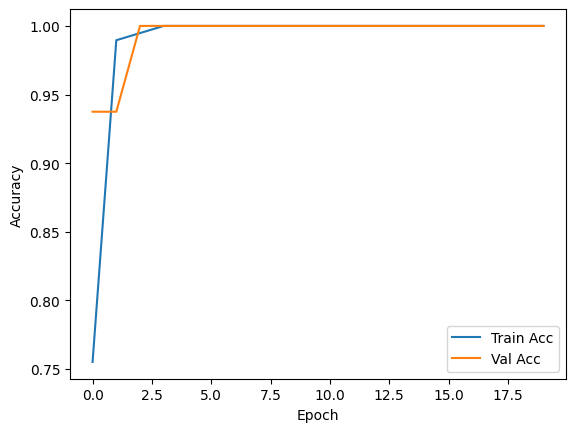

In [12]:
	plt.plot(history.history['accuracy'], label='Train Acc')
	plt.plot(history.history['val_accuracy'], label='Val Acc')
	plt.xlabel('Epoch')
	plt.ylabel('Accuracy')
	plt.legend()
	plt.show()

Dari grafik tersebut, apa yang bisa Anda interpretasikan?

Langkah 11 - Simpan Model
Simpan model untuk kebutuhan produksi.

In [13]:
	model.save('day_night_classifier_model.h5')